# La densité d'énergie du vide

Les calculs de la fiche [`README.md`](README.md).

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

sp.init_printing(use_latex="mathjax")

# Palette Smoothop (docs/Style.md § Les couleurs)
S3, O3, V5, K7 = "#0B85A6", "#CC6318", "#8D2EFF", "#606060"
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
from scipy import constants as K

## 1. L'intégrale avec coupure

$$\rho = \int_{|\mathbf{k}|<k_{\max}} \frac{d^3k}{(2\pi)^3}\,\frac{1}{2}\hbar c\,k$$

In [2]:
k, kmax, hbar, c = sp.symbols("k k_max hbar c", positive=True)
rho = sp.integrate(4*sp.pi*k**2 / (2*sp.pi)**3 * hbar*c*k/2, (k, 0, kmax))
rho

        4
c⋅h̅⋅kₘₐₓ 
─────────
      2  
  16⋅π   

## 2. Les ordres de grandeur

Coupure de Planck d'un côté, constante cosmologique observée de l'autre ($H_0 = 67{,}7$ km/s/Mpc, $\Omega_\Lambda = 0{,}69$).

In [3]:
l_P = np.sqrt(K.hbar * K.G / K.c**3)
rho_planck = K.hbar * K.c / (16 * np.pi**2 * l_P**4)

H0 = 67.7e3 / (1e6 * K.parsec)              # s^-1
Omega_L = 0.69
rho_L = Omega_L * 3 * H0**2 / (8 * np.pi * K.G) * K.c**2

print(f"longueur de Planck    l_P      = {l_P:.3e} m")
print(f"vide, coupure Planck  rho_P    = {rho_planck:.2e} J/m^3")
print(f"vide, observé         rho_Lam  = {rho_L:.2e} J/m^3")
print(f"rapport                          10^{np.log10(rho_planck / rho_L):.1f}")

longueur de Planck    l_P      = 1.616e-35 m
vide, coupure Planck  rho_P    = 2.93e+111 J/m^3
vide, observé         rho_Lam  = 5.34e-10 J/m^3
rapport                          10^120.7


## 3. Le vide d'une grille cubique

Sur une grille de pas $a$ : $\omega(\mathbf{k}) = \frac{2c}{a}\sqrt{\sum_i \sin^2(k_i a/2)}$, $\mathbf{k}$ dans la zone de Brillouin. Avec $\mathbf{q} = \mathbf{k}a$ :

$$\rho = \frac{\hbar c}{a^4}\,C, \qquad C = \frac{1}{(2\pi)^3}\int_{[-\pi,\pi]^3} \sqrt{\textstyle\sum_i \sin^2(q_i/2)}\;d^3q ,$$

soit la moyenne de $\sqrt{\sum_i \sin^2(q_i/2)}$ sur le cube. Intégration par points milieux, en raffinant pour voir la convergence.

In [4]:
def constante_grille(n):
    q = (np.arange(n) + 0.5) / n * 2*np.pi - np.pi
    s = np.sin(q/2)**2
    return np.sqrt(s[:, None, None] + s[None, :, None] + s[None, None, :]).mean()

for n in (25, 50, 100, 200):
    print(f"n = {n:3d}   C = {constante_grille(n):.6f}")
C_grille = constante_grille(200)
print(f"comparaison, continu coupé à la sphère |k| < pi/a : pi^2/16 = {np.pi**2/16:.6f}")

n =  25   C = 1.193799
n =  50   C = 1.193801
n = 100   C = 1.193801
n = 200   C = 1.193801
comparaison, continu coupé à la sphère |k| < pi/a : pi^2/16 = 0.616850


Quel pas de grille faudrait-il pour retrouver la valeur observée ?

In [5]:
a_requis = (C_grille * K.hbar * K.c / rho_L) ** 0.25
print(f"a = {a_requis:.2e} m  (≈ {a_requis*1e3:.2f} mm)")

a = 9.17e-05 m  (≈ 0.09 mm)


Un dixième de millimètre : une grille aussi grossière serait visible partout. La grille donne une énergie du vide finie, mais pas la bonne : le problème change de forme, il ne disparaît pas.

La relation de dispersion de la grille, le long d'un axe, comparée au continu :

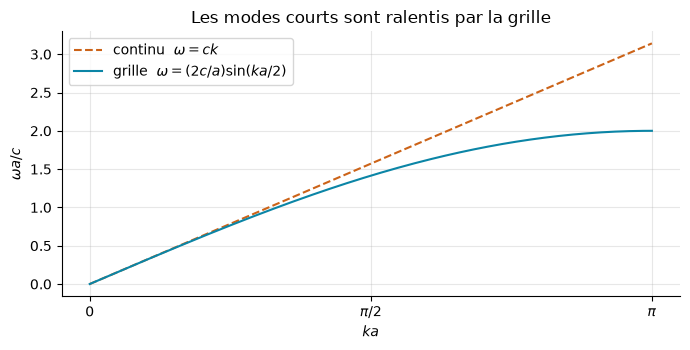

In [6]:
ka = np.linspace(0, np.pi, 200)
plt.plot(ka, ka, color=O3, ls="--", label=r"continu  $\omega = ck$")
plt.plot(ka, 2*np.sin(ka/2), color=S3, label=r"grille  $\omega = (2c/a)\sin(ka/2)$")
plt.xlabel(r"$ka$"); plt.ylabel(r"$\omega a / c$")
plt.xticks([0, np.pi/2, np.pi], ["0", r"$\pi/2$", r"$\pi$"])
plt.title("Les modes courts sont ralentis par la grille")
plt.legend(); plt.tight_layout()

## 4. L'effet Casimir

$$\frac{F}{A} = -\frac{\pi^2\hbar c}{240\,d^4}$$

pression à d = 1 µm : 1.30 mPa


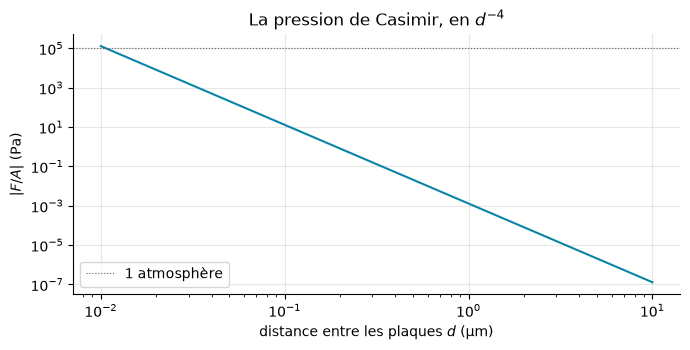

In [7]:
d = np.logspace(-8, -5, 200)              # de 10 nm à 10 µm
P = np.pi**2 * K.hbar * K.c / (240 * d**4)
print(f"pression à d = 1 µm : {np.pi**2 * K.hbar * K.c / (240 * 1e-6**4) * 1e3:.2f} mPa")

plt.loglog(d * 1e6, P, color=S3)
plt.axhline(K.atm, color=K7, ls=":", lw=0.8, label="1 atmosphère")
plt.xlabel(r"distance entre les plaques $d$ (µm)"); plt.ylabel(r"$|F/A|$ (Pa)")
plt.title("La pression de Casimir, en $d^{-4}$")
plt.legend(); plt.tight_layout()

**Lecture.** À 10 nm, le vide pousse les plaques avec environ une atmosphère. L'énergie absolue du vide reste insaisissable ; ses différences, elles, se mesurent.